# Dry Bean: multiclass classification
Compare validation-tuned XGBoost and LightGBM with frozen TabPFN-3.5-Fast and Mitra v2 on seven bean varieties. Every model uses the same seed-42 stratified 60/20/20 split. **Macro-F1** is primary (higher is better), with weighted-F1 and accuracy alongside it. Per-class scores and confusion matrices retain the original class names.

Source: [UCI Dry Bean](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset), Koklu and Ozkan (2020), [DOI 10.24432/C50S4B](https://doi.org/10.24432/C50S4B), **CC BY 4.0**. The release contains 13,611 observations, 16 numerical predictors, and seven classes. We use the archive's ARFF file and pin both archive and ARFF SHA-256 hashes.

In [1]:
from pathlib import Path
import os
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src/benchmark.py").exists())
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix
from src.benchmark import save_results
from src.data import make_split, RANDOM_STATE
from src.datasets import load_dry_bean
from src.evaluation import comparison_table
from src.experiments import run_isolated_comparison
from src.features import BeanFeatures
from src.models.classical import make_classical_models, classical_search_spaces
from src.models.tabpfn import make_tabpfn_models
from src.models.mitra import make_mitra_models
from src.plotting import plot_comparison
from src.preprocessing import make_preprocessor

SEED = RANDOM_STATE
PROFILE = os.environ.get("BENCHMARK_PROFILE", "full")  # full or smoke
DEVICE = os.environ.get("BENCHMARK_DEVICE", "auto")  # CUDA for full foundation-model runs
MODEL_TIMEOUT = float(os.environ.get("BENCHMARK_MODEL_TIMEOUT", "300"))
DOWNLOAD_DATA = True
DOWNLOAD_WEIGHTS = False  # Pre-cache pinned weights; see docs/dry-bean.md.
assert PROFILE in {"full", "smoke"}
OUTPUT = ROOT / "results/dry-bean" / PROFILE
OUTPUT.mkdir(parents=True, exist_ok=True)
print(f"Profile={PROFILE}; device={DEVICE}; per-model budget={MODEL_TIMEOUT:g}s; seed={SEED}")

Profile=full; device=cuda; per-model budget=300s; seed=42


## Load, validate, and split
The loader checks both hashes, exact feature names/order, row count, positive finite numerical values, missing values, and the seven class counts. `Class` is removed from predictors and decoded to the original string labels. The ARFF names `AspectRation` and `roundness` are retained exactly as released. No identifiers or extra spreadsheet columns enter the experiment.

The full profile retains all rows, including 68 identical full records. The optional **smoke** profile uses an explicitly labeled, stratified 500-row sample and writes separate artifacts. There is no automatic sampling to accommodate a model.

In [2]:
X, y, source = load_dry_bean(download=DOWNLOAD_DATA)
if PROFILE == "smoke":
    selected, _ = train_test_split(np.arange(len(y)), train_size=500, stratify=y, random_state=SEED)
    selected = np.sort(selected)
    X, y = X.iloc[selected].copy(), y.iloc[selected].copy()

splits = make_split(y.to_numpy(), "multiclass", SEED)
protocol = {"split_method": "stratified random 60/20/20", "seed": SEED,
    "primary_metric": "macro_f1", "refit_on_train_plus_validation": False,
    "class_balancing": "none", "duplicate_policy": "retain all source rows"}
split_record = {key: positions.tolist() for key, positions in splits.items()}
(OUTPUT / "splits.json").write_text(json.dumps({"seed": SEED, "profile": PROFILE,
    "protocol": protocol, "source_row_positions": X.index.tolist(), "splits": split_record}, indent=2) + "\n")
display(pd.DataFrame([{"partition": key, "rows": len(positions), "classes": y.iloc[positions].nunique()}
    for key, positions in splits.items()]).set_index("partition"))
display(pd.DataFrame({key: y.iloc[positions].value_counts() for key, positions in splits.items()}).sort_index())
print(f"Predictors: {X.shape[1]}; source identical full rows retained: {source['identical_full_rows']}")
print("Archive SHA-256:", source["archive_sha256"])
print("ARFF SHA-256:", source["arff_sha256"])
assert "Class" not in X.columns

,rows,classes
partition,,
train,8166,7
validation,2722,7
test,2723,7


,train,validation,test
Class,,,
BARBUNYA,793,265,264
BOMBAY,313,105,104
CALI,978,326,326
DERMASON,2127,709,710
HOROZ,1157,385,386
SEKER,1216,405,406
SIRA,1582,527,527


Predictors: 16; source identical full rows retained: 68
Archive SHA-256: 0a64eff5be87f48c3dbbfc0a12a56c5d5b5167ef8e61cd45d69b3e7c7130c06f
ARFF SHA-256: b2a4a76a2aedfb8ed415adfc1bfc70b5f202cb00cb72e500766e364c14834014


## Training-data exploration
Explore training predictors only when preparing the experiment. Partition class counts above describe the frozen stratified split. All seven classes are present in each partition, with imbalance handled by reporting macro-F1 and per-class results. No feature or model decision uses a test score.

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
636,37179.0,704.496,240.383587,197.179245,1.219112,0.571978,37555.0,217.572455,0.771669,0.989988,0.941349,0.905105,0.006466,0.002677,0.819216,0.998716
9351,47446.0,835.604,321.134469,188.419866,1.704356,0.809781,47952.0,245.784710,0.678760,0.989448,0.853903,0.765364,0.006768,0.001433,0.585782,0.998381
3424,148931.0,1403.498,496.126875,382.826994,1.295956,0.636070,149919.0,435.459342,0.823961,0.993410,0.950104,0.877718,0.003331,0.001220,0.770388,0.998389
4868,77107.0,1073.559,415.676982,237.312060,1.751605,0.821016,77867.0,313.329988,0.796017,0.990240,0.840721,0.753782,0.005391,0.001074,0.568188,0.995241
1144,39984.0,729.801,254.431815,200.581162,1.268473,0.615228,40353.0,225.630694,0.820892,0.990856,0.943381,0.886802,0.006363,0.002428,0.786418,0.997550


,dtype,missing,unique_training_values
Area,float64,0,7540
Perimeter,float64,0,8096
MajorAxisLength,float64,0,8144
MinorAxisLength,float64,0,8144
AspectRation,float64,0,8144
Eccentricity,float64,0,8144
ConvexArea,float64,0,7604
EquivDiameter,float64,0,7540
Extent,float64,0,8142
Solidity,float64,0,8139


,count,mean,std,min,25%,50%,75%,max
Area,8166.0,52936.493877,29191.586185,20420.000000,36209.250000,44672.000000,61235.000000,248424.000000
Perimeter,8166.0,854.365557,213.293569,524.932000,702.524000,795.031000,975.891000,1895.940000
MajorAxisLength,8166.0,319.797900,85.283671,183.601165,253.025436,297.260628,375.666018,726.373493
MinorAxisLength,8166.0,202.107847,44.881304,122.512653,175.757874,192.418646,216.469268,460.198497
AspectRation,8166.0,1.582861,0.245585,1.036423,1.434210,1.551106,1.705878,2.430306
Eccentricity,8166.0,0.750955,0.091707,0.262774,0.716830,0.764435,0.810160,0.911423
ConvexArea,8166.0,53654.350478,29629.939382,20684.000000,36609.250000,45206.000000,62224.500000,251082.000000
EquivDiameter,8166.0,252.830793,58.973329,161.243764,214.716206,238.491419,279.225399,562.408446
Extent,8166.0,0.749340,0.049068,0.566768,0.718445,0.759160,0.786509,0.858420
Solidity,8166.0,0.987123,0.004702,0.943559,0.985636,0.988282,0.990006,0.994677


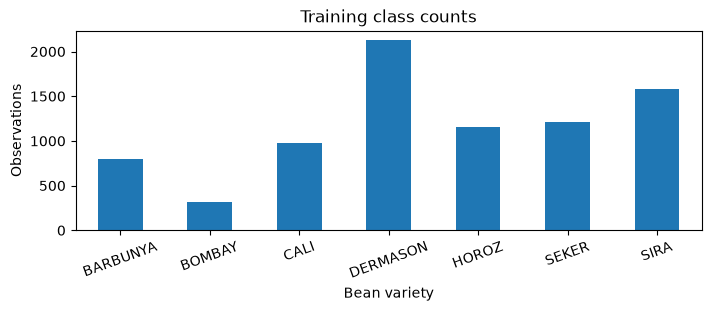

In [3]:
training = X.iloc[splits["train"]]
display(training.head())
display(pd.DataFrame({"dtype": training.dtypes.astype(str), "missing": training.isna().sum(),
    "unique_training_values": training.nunique()}))
display(training.describe().T)
figure, axis = plt.subplots(figsize=(7, 3), layout="constrained")
y.iloc[splits["train"]].value_counts().sort_index().plot.bar(ax=axis, rot=20)
axis.set(title="Training class counts", xlabel="Bean variety", ylabel="Observations")
plt.show()

## Predeclared model and feature settings
Raw foundation-model runs use all 16 released numerical measurements with native train-only preprocessing. The source already includes shape ratios. To keep an explicit engineered comparison, we retain the originals and add four natural-log size representations: area, perimeter, major-axis length, and minor-axis length. These fixed, row-local transformations compress multiplicative size variation, add no new measured information, and are not chosen using test scores. The loader validates their strictly positive domain.

Both classical models use the engineered frame with train-only imputation/scaling. Each uses the shared four-candidate, 80-tree validation grid selected by macro-F1. Foundation models use pinned frozen weights, without validation tuning or fine-tuning; TabPFN uses its auto ensemble and Mitra uses one estimator. The dummy predicts the training majority class while exposing training-prior probabilities. There is no resampling, class balancing, threshold tuning, or train-plus-validation refit.

In [4]:
models = {"Dummy prior": DummyClassifier(strategy="prior", random_state=SEED)}
models.update(make_classical_models("multiclass", SEED))
models.update(make_tabpfn_models("multiclass", SEED, DEVICE, download=DOWNLOAD_WEIGHTS))
models.update(make_mitra_models("multiclass", SEED, DEVICE, download=DOWNLOAD_WEIGHTS))
models["TabPFN - Engineered"] = make_tabpfn_models("multiclass", SEED, DEVICE, download=DOWNLOAD_WEIGHTS)["TabPFN - Raw"]
models["Mitra v2 - Engineered"] = make_mitra_models("multiclass", SEED, DEVICE, download=DOWNLOAD_WEIGHTS)["Mitra v2 - Raw"]

# Choosing column names from a transformed training frame learns no holdout information.
engineered_training = BeanFeatures().fit_transform(training)
classical_preprocessor = Pipeline([
    ("features", BeanFeatures()), ("encoding", make_preprocessor(engineered_training)),
])
preprocessors = {name: classical_preprocessor for name in ("XGBoost", "LightGBM")}
preprocessors.update({name: BeanFeatures() for name in ("TabPFN - Engineered", "Mitra v2 - Engineered")})
search_spaces = classical_search_spaces()
for name, model in models.items():
    print(name, "— validation grid" if name in search_spaces else "— fixed inference")

Dummy prior — fixed inference
XGBoost — validation grid
LightGBM — validation grid
TabPFN - Raw — fixed inference
Mitra v2 - Raw — fixed inference
TabPFN - Engineered — fixed inference
Mitra v2 - Engineered — fixed inference


## Execute the comparison
Each independent, predeclared recipe runs in its own process to release model/GPU memory on exit. Selection uses training and validation only; the selected model is then scored on the test partition. Earlier test scores do not alter later recipes. The timeout includes loading, tuning, and prediction. A model that exceeds the budget or available memory is **Not evaluated**, with a reason and no metric values. Inputs are never silently subsampled to make a model run. Unexpected implementation failures remain distinct and fail the notebook after diagnostic artifacts are saved.

The full training context contains 8,166 observations, within Mitra's configured 8,192-row limit. CUDA is appropriate because this exceeds TabPFN's default CPU row limit. Context rows are never silently dropped.

In [5]:
results = run_isolated_comparison(
    X, y, models, task="multiclass", dataset_name=f"Dry Bean ({PROFILE}, {len(X):,} rows)",
    seed=SEED, splits=splits, search_spaces=search_spaces,
    preprocessors=preprocessors, timeout=MODEL_TIMEOUT, output_path=OUTPUT / "results.json",
)
results["dataset"].update({"profile": PROFILE, "source": source, "source_row_positions": X.index.tolist()})
results["protocol"] = protocol
results["split_method"] = "random-stratified"
results["checkpoint_manifest"] = json.loads((ROOT / "checkpoints/manifest.json").read_text())
results["feature_engineering"] = {"added": list(BeanFeatures.added),
    "classical_setting": "engineered", "foundation_settings": ["raw", "engineered"],
    "transform": "natural log of area, perimeter, major/minor axis lengths; originals retained",
    "class_thresholds": "none; model default argmax"}
save_results(results, OUTPUT / "results.json")

Running Dummy prior...


Dummy prior: evaluated


Running XGBoost...


XGBoost: evaluated


Running LightGBM...


...

Mitra v2 - Raw: evaluated


Running TabPFN - Engineered...


TabPFN - Engineered: evaluated


Running Mitra v2 - Engineered...


Mitra v2 - Engineered: evaluated


## Final test metrics and per-class results
Macro-F1 weights each class equally; weighted-F1 weights by test support. Accuracy alone can obscure minority-class performance. Scores are derived from saved label predictions, with explicit probability-column class order preserved in the artifacts. Per-class F1 below and exported precision/recall/support provide context for all models. Confusion matrices are exported with explicit true/predicted axes and original class labels. Empty scores indicate an unevaluated model with a recorded reason.

In [6]:
status = pd.DataFrame([{"model": row["name"],
    "status": "Evaluated" if row["status"] == "evaluated" else "Not evaluated" if row["status"] == "unavailable" else "Failed",
    "reason": row.get("reason", ""), "seconds": row["elapsed_seconds"]} for row in results["models"]]).set_index("model")
table = comparison_table(results)
export = table.join(status)
export.to_csv(OUTPUT / "metrics.csv")
display(export.style.format({column: "{:.4f}" for column in table.columns}, na_rep="Not evaluated"))
print("Profile:", PROFILE, "—", "full released dataset" if PROFILE == "full" else "SMOKE SAMPLE; not full benchmark results")

# Preserve label order explicitly in every per-class report and confusion matrix.
per_class_rows, matrices = [], {}
for row in results["models"]:
    if row["status"] != "evaluated":
        continue
    labels = row["classes"]
    predictions = row["predictions"]["test"]["values"]
    report = classification_report(results["targets"]["test"], predictions,
        labels=labels, output_dict=True, zero_division=0)
    for label in labels:
        per_class_rows.append({"model": row["name"], "class": label, **report[label]})
    matrices[row["name"]] = {"labels": labels, "rows": "true", "columns": "predicted",
        "counts": confusion_matrix(results["targets"]["test"], predictions, labels=labels).tolist()}
per_class = pd.DataFrame(per_class_rows, columns=["model", "class", "precision", "recall", "f1-score", "support"])
per_class.to_csv(OUTPUT / "per_class_metrics.csv", index=False)
(OUTPUT / "confusion_matrices.json").write_text(json.dumps(matrices, indent=2) + "\n")
if not per_class.empty:
    display(Markdown("**Test F1 by class** (all evaluated models)"))
    display(per_class.pivot(index="model", columns="class", values="f1-score").style.format("{:.4f}"))

,macro_f1,weighted_f1,accuracy,status,reason,seconds
model,,,,,,
Dummy prior,0.0591,0.1079,0.2607,Evaluated,,3.700434
XGBoost,0.9334,0.9202,0.9203,Evaluated,,5.291338
LightGBM,0.9336,0.9200,0.9203,Evaluated,,4.357033
TabPFN - Raw,0.9390,0.9264,0.9266,Evaluated,,19.469507
Mitra v2 - Raw,0.9370,0.9239,0.9243,Evaluated,,192.770055
TabPFN - Engineered,0.9381,0.9250,0.9251,Evaluated,,21.264358
Mitra v2 - Engineered,0.9372,0.9246,0.9251,Evaluated,,230.113993


Profile: full — full released dataset


**Test F1 by class** (all evaluated models)

class,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA
model,,,,,,,
Dummy prior,0.0000,0.0000,0.0000,0.4136,0.0000,0.0000,0.0000
LightGBM,0.9261,1.0000,0.9464,0.9120,0.9566,0.9438,0.8505
Mitra v2 - Engineered,0.9290,1.0000,0.9522,0.9193,0.9576,0.9428,0.8597
Mitra v2 - Raw,0.9308,1.0000,0.9524,0.9163,0.9576,0.9440,0.8580
TabPFN - Engineered,0.9310,1.0000,0.9552,0.9161,0.9590,0.9452,0.8599
TabPFN - Raw,0.9290,1.0000,0.9568,0.9175,0.9590,0.9467,0.8640
XGBoost,0.9213,1.0000,0.9467,0.9141,0.9577,0.9425,0.8512


## Primary-metric comparison
The plot compares measured test macro-F1 (higher is better). Only evaluated models appear in the plot; every attempted model remains in the table above.

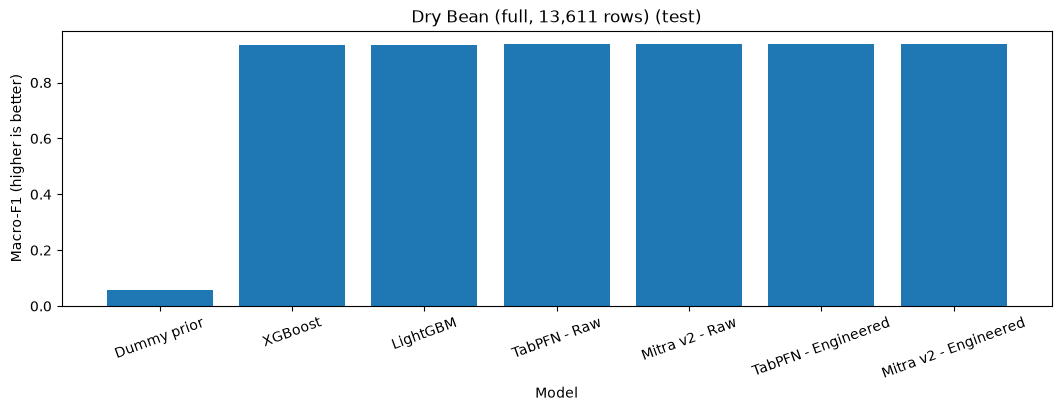

In [7]:
figure = plot_comparison(results)
figure.savefig(OUTPUT / "macro_f1.png", dpi=150)
plt.show()

## Observations and limitations
This is a descriptive comparison on one fixed stratified split, without significance testing or claims of universal superiority. The released shape measurements are already extracted from images; this experiment does not evaluate image acquisition or segmentation. All 68 identical full records remain in the source. Row positions are disjoint, but repeated measurements can span partitions and limit independence; source identifiers are unavailable for a group-based analysis. Results do not establish performance on unseen collection sites or future image-processing pipelines.

The saved artifact records source/split positions, hashes, recipes, selected settings, validation trials, predictions, class order, versions, checkpoint/runtime details, and any unavailable-model reasons. Per-class metrics and confusion matrices are derived from those same saved test predictions.

In [8]:
ranked = table["macro_f1"].dropna().sort_values(ascending=False)
if not ranked.empty:
    display(Markdown(f"Highest observed test macro-F1: **{ranked.index[0]}**, **{ranked.iloc[0]:.4f}** ({PROFILE} profile)."))
not_evaluated = status[status["status"] != "Evaluated"]
if not not_evaluated.empty:
    display(not_evaluated[["status", "reason"]])
print("Artifacts:", OUTPUT.relative_to(ROOT))
failed = [row["name"] for row in results["models"] if row["status"] == "failed"]
assert not failed, f"Unexpected model failures require investigation: {failed}"

Highest observed test macro-F1: **TabPFN - Raw**, **0.9390** (full profile).

Artifacts: results/dry-bean/full
